# QUBO e Ising

La convenzione di conversione è:

```text
delta_i = (1 + z_i) / 2
z_i = 2 * delta_i - 1
```

Le energie includono gli offset.

In [1]:
import pandas as pd
from IPython.display import display

from qreduce.notebooks.examples import energy_example
from qreduce.notebooks.plots import plot_reduction_graph

example = energy_example()

## Grafo di input

Nodi, pesi e archi definiscono l’istanza MWIS. Il layout è illustrativo.


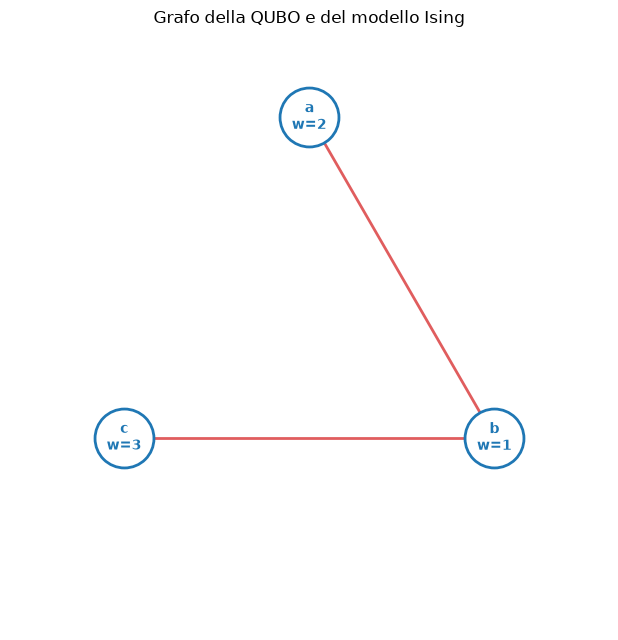

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plot_reduction_graph(example["graph"], title="Grafo della QUBO e del modello Ising")
plt.show()

## Rappresentazioni derivate: QUBO e Ising

I coefficienti sono costruiti dal grafo e dalla penalità, prima della valutazione delle energie.


In [3]:
display(pd.Series(example["qubo"], name="QUBO").to_frame())
display(pd.Series(example["ising"], name="Ising").to_frame())

,QUBO
variable_domain,binary
node_order,"[a, b, c]"
linear,"{'a': -2.0, 'b': -1.0, 'c': -3.0}"
quadratic,"[{'edge': ['a', 'b'], 'coefficient': 4.0}, {'e..."
offset,0.0
lambda_edge,4.0
proof_condition_satisfied,True


,Ising
variable_domain,spin
node_order,"[a, b, c]"
linear,"{'a': 0.0, 'b': 1.5, 'c': -0.5}"
quadratic,"[{'edge': ['a', 'b'], 'coefficient': 1.0}, {'e..."
offset,-1.0
binary_to_spin_convention,delta_i = (1 + z_i) / 2; z_i = 2 * delta_i - 1


## Energie calcolate per tutte le configurazioni


In [4]:
energies = pd.DataFrame(example["energies"])
display(energies)

,delta,z_spin,qubo_energy,ising_energy,independent
0,"(0, 0, 0)","(-1, -1, -1)",0.0,0.0,True
1,"(0, 0, 1)","(-1, -1, 1)",-3.0,-3.0,True
2,"(0, 1, 0)","(-1, 1, -1)",-1.0,-1.0,True
3,"(0, 1, 1)","(-1, 1, 1)",0.0,0.0,False
4,"(1, 0, 0)","(1, -1, -1)",-2.0,-2.0,True
5,"(1, 0, 1)","(1, -1, 1)",-5.0,-5.0,True
6,"(1, 1, 0)","(1, 1, -1)",1.0,1.0,False
7,"(1, 1, 1)","(1, 1, 1)",2.0,2.0,False


<Axes: title={'center': 'Energie QUBO e Ising'}, xlabel='Configurazione'>

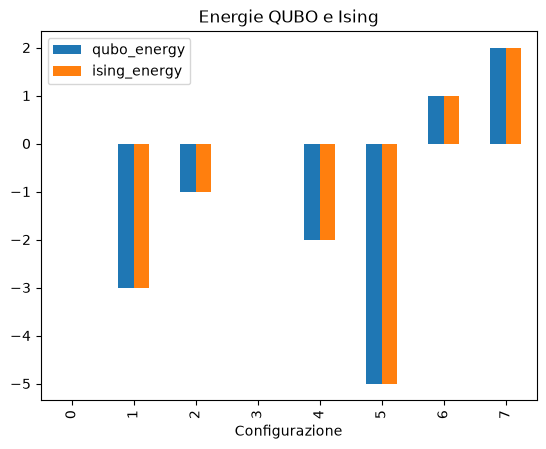

In [5]:
energies[["qubo_energy", "ising_energy"]].plot.bar(title="Energie QUBO e Ising", xlabel="Configurazione")